In [1]:
import sys, json, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import yaml, timm, torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,roc_auc_score, confusion_matrix)
from tqdm.auto import tqdm       

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.datasets import Preprocessor, PlantDataset      
import mlflow
from src import tracking
tracking.setup(PROJECT_ROOT, "plant-disease-transfer-learning")  

In [3]:
CFG       = yaml.safe_load((PROJECT_ROOT / "configs" / "base.yaml").read_text())
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
META      = json.loads((SPLIT_DIR / "meta.json").read_text())
CLASSES, DATA_ROOT = META["classes"], META["data_root"]
NUM_CLASSES = len(CLASSES)

TIMM_NAME  = "tf_efficientnetv2_s"
STRATEGIES = ["feature_extraction", "partial", "full"]
PARTIAL_BLOCKS = 2                       

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| classes:", NUM_CLASSES)

Device: cuda | classes: 21


In [4]:
def set_seed(seed):
    import random
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

pcfg = timm.models.get_pretrained_cfg(TIMM_NAME)
prep = Preprocessor(CFG["img_size"], tuple(pcfg.mean), tuple(pcfg.std))

loaders = {
    name: DataLoader(PlantDataset(SPLIT_DIR / f"{name}.csv", DATA_ROOT, prep),
    batch_size=CFG["batch_size"], shuffle=(name == "train"),
    num_workers=2, pin_memory=(DEVICE == "cuda"))
    for name in ["train", "val", "test"]
}
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 28156, 'val': 6033, 'test': 6034}


In [5]:
class EfficientNetV2Builder:
    """Builds EfficientNetV2 and applies one transfer-learning strategy.
       feature_extraction : backbone frozen, only the new classifier head trains
       partial            : head + last N stages (+ conv_head/bn2) train, rest frozen
       full               : everything trains"""

    def __init__(self, timm_name, num_classes, partial_blocks=2):
        self.timm_name, self.num_classes, self.partial_blocks = timm_name, num_classes, partial_blocks

    def build(self, strategy: str) -> nn.Module:
        model = timm.create_model(self.timm_name, pretrained=True, num_classes=self.num_classes)
        self._apply_strategy(model, strategy)
        return model

    def _apply_strategy(self, model, strategy):
        for p in model.parameters():
            p.requires_grad = False

        if strategy == "full":
            for p in model.parameters():
                p.requires_grad = True
        else:
            for p in model.get_classifier().parameters():       
                p.requires_grad = True
            if strategy == "partial":
                last_stages = list(model.blocks.children())[-self.partial_blocks:]
                for module in [*last_stages, model.conv_head, model.bn2]:
                    for p in module.parameters():
                        p.requires_grad = True
            elif strategy != "feature_extraction":
                raise ValueError(f"Unknown strategy: {strategy}")

    @staticmethod
    def param_groups(model, lr_head, lr_backbone):
        head_ids = {id(p) for p in model.get_classifier().parameters()}
        head = [p for p in model.parameters() if id(p) in head_ids]
        back = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
        groups = [{"params": head, "lr": lr_head}]
        if back:
            groups.append({"params": back, "lr": lr_backbone})
        return groups

    @staticmethod
    def count_params(model):
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        return total, trainable

In [6]:
builder = EfficientNetV2Builder(TIMM_NAME, NUM_CLASSES, PARTIAL_BLOCKS)
for s in STRATEGIES:
    total, trainable = builder.count_params(builder.build(s))
    print(f"{s:<20} trainable {trainable:>10,} / {total:,}  ({trainable/total:.1%})")

feature_extraction   trainable     26,901 / 20,204,389  (0.1%)
partial              trainable 18,382,813 / 20,204,389  (91.0%)
full                 trainable 20,204,389 / 20,204,389  (100.0%)


In [7]:
class EarlyStopping:
    """Stops when the monitored metric stops improving, keeps the best weights."""
    def __init__(self, patience=5, min_delta=0.0, mode="min", restore_best=True):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.restore_best = restore_best
        self.best = float("inf") if mode == "min" else -float("inf")
        self.best_epoch, self.best_state, self.wait, self.stop = 0, None, 0, False

    def _improved(self, v):
        return v < self.best - self.min_delta if self.mode == "min" else v > self.best + self.min_delta

    def __call__(self, value, model, epoch):
        if self._improved(value):
            self.best, self.best_epoch, self.wait = value, epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.wait += 1
            self.stop = self.wait >= self.patience

    def restore(self, model):
        if self.restore_best and self.best_state is not None:
            model.load_state_dict(self.best_state)

In [8]:
class Trainer:
    """verbose: 0 = silent | 1 = one line per epoch | 2 = + batch progress bars"""

    def __init__(self, model, loaders, cfg, param_groups, device, verbose=1):
        self.verbose = verbose
        self.model, self.loaders, self.cfg, self.device = model.to(device), loaders, cfg, device
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(param_groups)
        self.use_amp   = device == "cuda"
        self.scaler    = torch.amp.GradScaler("cuda", enabled=self.use_amp)
        self.early_stopping = EarlyStopping(
            patience=cfg["early_stopping_patience"],
            min_delta=cfg.get("early_stopping_min_delta", 0.0),
            mode="min",
        )

    def _freeze_bn_if_frozen(self):
        for m in self.model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                if not any(p.requires_grad for p in m.parameters()):
                    m.eval()

    def _run_epoch(self, loader, train: bool, desc=""):
        self.model.train(train)
        if train:
            self._freeze_bn_if_frozen()
        loss_sum, correct, n = 0.0, 0, 0
        it = tqdm(loader, desc=desc, leave=False) if self.verbose >= 2 else loader
        with torch.set_grad_enabled(train):
            for x, y in it:
                x, y = x.to(self.device, non_blocking=True), y.to(self.device, non_blocking=True)
                with torch.autocast(self.device, enabled=self.use_amp):
                    out  = self.model(x)
                    loss = self.criterion(out, y)
                if train:
                    self.optimizer.zero_grad(set_to_none=True)
                    self.scaler.scale(loss).backward()
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                loss_sum += loss.item() * x.size(0)
                correct  += (out.argmax(1) == y).sum().item()
                n        += x.size(0)
                if self.verbose >= 2:
                    it.set_postfix(loss=f"{loss_sum / n:.4f}", acc=f"{correct / n:.4f}")
        return loss_sum / n, correct / n

    def fit(self):
        history, t0, E = [], time.time(), self.cfg["epochs"]
        for epoch in range(1, E + 1):
            t_ep = time.time()
            tr_loss, tr_acc = self._run_epoch(self.loaders["train"], True,  f"ep {epoch}/{E} train")
            va_loss, va_acc = self._run_epoch(self.loaders["val"],   False, f"ep {epoch}/{E} val  ")
            ep_time = time.time() - t_ep
            history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                                val_loss=va_loss, val_acc=va_acc, epoch_time_s=round(ep_time, 1)))

            if mlflow.active_run():
                mlflow.log_metrics({
                    "train_loss": tr_loss, "train_acc": tr_acc,
                    "val_loss": va_loss,   "val_acc": va_acc,
                    "epoch_time_s": ep_time,
                    "lr_head": self.optimizer.param_groups[0]["lr"],
                }, step=epoch)

            self.early_stopping(va_loss, self.model, epoch)

            if self.verbose >= 1:
                lrs  = "/".join(f"{g['lr']:.0e}" for g in self.optimizer.param_groups)
                flag = "  <- best" if self.early_stopping.best_epoch == epoch else ""
                print(f"ep {epoch:02d}/{E} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                      f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {lrs} | {ep_time:.0f}s | "
                      f"wait {self.early_stopping.wait}/{self.early_stopping.patience}{flag}", flush=True)

            if self.early_stopping.stop:
                if self.verbose >= 1:
                    print(f">> Early stopping at epoch {epoch} (best epoch "
                          f"{self.early_stopping.best_epoch}, val_loss {self.early_stopping.best:.4f})",
                          flush=True)
                break

        self.early_stopping.restore(self.model)
        return pd.DataFrame(history), time.time() - t0

    @torch.no_grad()
    def predict(self, loader):
        self.model.eval()
        probs, ys = [], []
        for x, y in loader:
            with torch.autocast(self.device, enabled=self.use_amp):
                out = self.model(x.to(self.device))
            probs.append(out.float().softmax(1).cpu().numpy())
            ys.append(y.numpy())
        return np.concatenate(ys), np.concatenate(probs)

In [9]:
def compute_metrics(y_true, y_prob):
    y_pred = y_prob.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": p, "recall": r, "f1": f1,                 # macro = every class counts equally
        "auc": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
    }

In [10]:
def run_experiment(strategy: str, verbose: int = 1, log_model: bool = False):
    set_seed(CFG["seed"])
    model = builder.build(strategy)
    total, trainable = builder.count_params(model)
    groups = builder.param_groups(model, lr_head=CFG["lr_feature_extraction"],
                                  lr_backbone=CFG["lr_finetune"])
    out = PROJECT_ROOT / "results" / f"efficientnetv2_{strategy}"
    out.mkdir(parents=True, exist_ok=True)

    with mlflow.start_run(run_name=f"efficientnetv2_{strategy}"):      
        mlflow.set_tags({"stage": "train", "model": TIMM_NAME, "strategy": strategy})
        mlflow.log_params({
            **tracking.flatten(CFG),                                   
            "model": TIMM_NAME, "strategy": strategy,
            "partial_blocks": PARTIAL_BLOCKS if strategy == "partial" else 0,
            "params_total": total, "params_trainable": trainable, "device": DEVICE,
        })

        trainer = Trainer(model, loaders, CFG, groups, DEVICE, verbose=verbose)
        print(f"\n=== {TIMM_NAME} | {strategy} | trainable {trainable:,}/{total:,} ===", flush=True)
        history, train_time = trainer.fit()

        y_true, y_prob = trainer.predict(loaders["test"])
        metrics = compute_metrics(y_true, y_prob)
        extra = dict(training_time_s=round(train_time, 1), epochs_run=len(history),best_epoch=trainer.early_stopping.best_epoch)
        mlflow.log_metrics({**{f"test_{k}": float(v) for k, v in metrics.items()}, **extra})

        metrics.update(params_total=total, params_trainable=trainable,
                       model=TIMM_NAME, strategy=strategy, **extra)

        history.to_csv(out / "history.csv", index=False)
        (out / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
        np.savez(out / "preds.npz", y_true=y_true, y_prob=y_prob)
        torch.save(model.state_dict(), out / "model.pt")
        (out / "config_used.yaml").write_text(yaml.safe_dump({**CFG, "strategy": strategy,
                                                              "partial_blocks": PARTIAL_BLOCKS}))

        for f in ["history.csv", "metrics.json", "preds.npz", "config_used.yaml"]:
            mlflow.log_artifact(str(out / f))
        if log_model:
            mlflow.log_artifact(str(out / "model.pt"), artifact_path="model")

    print("TEST:", {k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)}, flush=True)
    return metrics

In [11]:
# STRATEGIES = ["feature_extraction", "partial", "full"]

In [12]:
feature_extraction_metric = run_experiment('feature_extraction')


=== tf_efficientnetv2_s | feature_extraction | trainable 26,901/20,204,389 ===
ep 01/15 | train loss 0.9572 acc 0.7368 | val loss 0.4080 acc 0.8694 | lr 1e-03 | 104s | wait 0/5  <- best
ep 02/15 | train loss 0.3058 acc 0.9012 | val loss 0.2955 acc 0.9077 | lr 1e-03 | 91s | wait 0/5  <- best
ep 03/15 | train loss 0.2195 acc 0.9300 | val loss 0.2433 acc 0.9231 | lr 1e-03 | 98s | wait 0/5  <- best
ep 04/15 | train loss 0.1756 acc 0.9456 | val loss 0.2221 acc 0.9281 | lr 1e-03 | 99s | wait 0/5  <- best
ep 05/15 | train loss 0.1468 acc 0.9554 | val loss 0.2008 acc 0.9329 | lr 1e-03 | 91s | wait 0/5  <- best
ep 06/15 | train loss 0.1258 acc 0.9617 | val loss 0.1876 acc 0.9390 | lr 1e-03 | 89s | wait 0/5  <- best
ep 07/15 | train loss 0.1095 acc 0.9676 | val loss 0.1945 acc 0.9337 | lr 1e-03 | 92s | wait 1/5
ep 08/15 | train loss 0.0974 acc 0.9701 | val loss 0.1805 acc 0.9393 | lr 1e-03 | 83s | wait 0/5  <- best
ep 09/15 | train loss 0.0884 acc 0.9746 | val loss 0.1680 acc 0.9489 | lr 1e-03 

In [13]:
partial_metric = run_experiment('partial')


=== tf_efficientnetv2_s | partial | trainable 18,382,813/20,204,389 ===
ep 01/15 | train loss 0.9188 acc 0.7623 | val loss 0.3025 acc 0.9032 | lr 1e-03/1e-05 | 134s | wait 0/5  <- best
ep 02/15 | train loss 0.1926 acc 0.9353 | val loss 0.1977 acc 0.9392 | lr 1e-03/1e-05 | 126s | wait 0/5  <- best
ep 03/15 | train loss 0.0957 acc 0.9693 | val loss 0.1693 acc 0.9453 | lr 1e-03/1e-05 | 120s | wait 0/5  <- best
ep 04/15 | train loss 0.0586 acc 0.9806 | val loss 0.1511 acc 0.9533 | lr 1e-03/1e-05 | 126s | wait 0/5  <- best
ep 05/15 | train loss 0.0394 acc 0.9871 | val loss 0.1496 acc 0.9539 | lr 1e-03/1e-05 | 129s | wait 0/5  <- best
ep 06/15 | train loss 0.0295 acc 0.9910 | val loss 0.1374 acc 0.9627 | lr 1e-03/1e-05 | 119s | wait 0/5  <- best
ep 07/15 | train loss 0.0241 acc 0.9925 | val loss 0.1340 acc 0.9617 | lr 1e-03/1e-05 | 117s | wait 0/5  <- best
ep 08/15 | train loss 0.0206 acc 0.9926 | val loss 0.1530 acc 0.9606 | lr 1e-03/1e-05 | 117s | wait 1/5
ep 09/15 | train loss 0.0198 acc

In [14]:
full_metric = run_experiment('full')


=== tf_efficientnetv2_s | full | trainable 20,204,389/20,204,389 ===
ep 01/15 | train loss 0.9795 acc 0.7463 | val loss 0.3371 acc 0.8924 | lr 1e-03/1e-05 | 152s | wait 0/5  <- best
ep 02/15 | train loss 0.2222 acc 0.9262 | val loss 0.2230 acc 0.9319 | lr 1e-03/1e-05 | 150s | wait 0/5  <- best
ep 03/15 | train loss 0.1184 acc 0.9594 | val loss 0.1967 acc 0.9354 | lr 1e-03/1e-05 | 154s | wait 0/5  <- best
ep 04/15 | train loss 0.0721 acc 0.9755 | val loss 0.1631 acc 0.9514 | lr 1e-03/1e-05 | 178s | wait 0/5  <- best
ep 05/15 | train loss 0.0482 acc 0.9838 | val loss 0.1655 acc 0.9504 | lr 1e-03/1e-05 | 162s | wait 1/5
ep 06/15 | train loss 0.0367 acc 0.9883 | val loss 0.1569 acc 0.9582 | lr 1e-03/1e-05 | 167s | wait 0/5  <- best
ep 07/15 | train loss 0.0298 acc 0.9896 | val loss 0.1406 acc 0.9599 | lr 1e-03/1e-05 | 165s | wait 0/5  <- best
ep 08/15 | train loss 0.0229 acc 0.9923 | val loss 0.1538 acc 0.9620 | lr 1e-03/1e-05 | 161s | wait 1/5
ep 09/15 | train loss 0.0211 acc 0.9928 | va

In [15]:
all_metrics = [feature_extraction_metric,partial_metric,full_metric]

In [16]:
summary = pd.DataFrame(all_metrics).set_index("strategy")
cols = ["accuracy", "precision", "recall", "f1", "auc","params_trainable", "params_total", "training_time_s", "epochs_run"]

display(summary[cols].round(4))
summary_path = PROJECT_ROOT / "results" / "summary.csv"
old = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()

new = pd.concat(
    [old[~((old.get("model") == TIMM_NAME))] if len(old) else old,
    summary.reset_index()], ignore_index=True
)     
new.to_csv(summary_path, index=False)

,accuracy,precision,recall,f1,auc,params_trainable,params_total,training_time_s,epochs_run
strategy,,,,,,,,,
feature_extraction,0.9490,0.9594,0.9598,0.9595,0.9986,26901,20204389,1363.9,15
partial,0.9664,0.9733,0.9740,0.9736,0.9993,18382813,20204389,1463.5,12
full,0.9713,0.9779,0.9780,0.9779,0.9994,20204389,20204389,2505.2,15


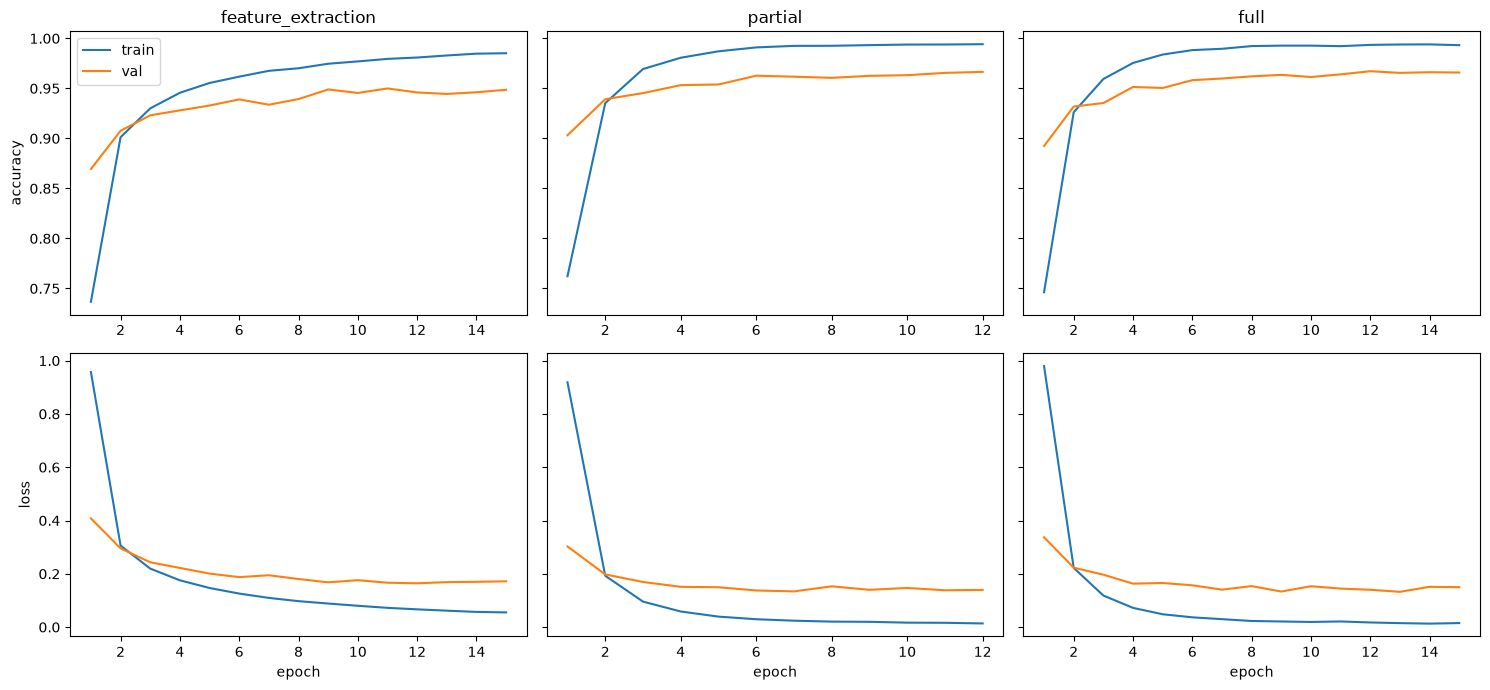

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for j, s in enumerate(STRATEGIES):
    
    h = pd.read_csv(PROJECT_ROOT / "results" / f"efficientnetv2_{s}" / "history.csv")
    axes[0, j].plot(h.epoch, h.train_acc, label="train"); axes[0, j].plot(h.epoch, h.val_acc, label="val")
    axes[1, j].plot(h.epoch, h.train_loss, label="train"); axes[1, j].plot(h.epoch, h.val_loss, label="val")
    axes[0, j].set_title(s); axes[1, j].set_xlabel("epoch")
    
axes[0, 0].set_ylabel("accuracy"); axes[1, 0].set_ylabel("loss"); axes[0, 0].legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "efficientnetv2_curves.png", dpi=150)
plt.show()

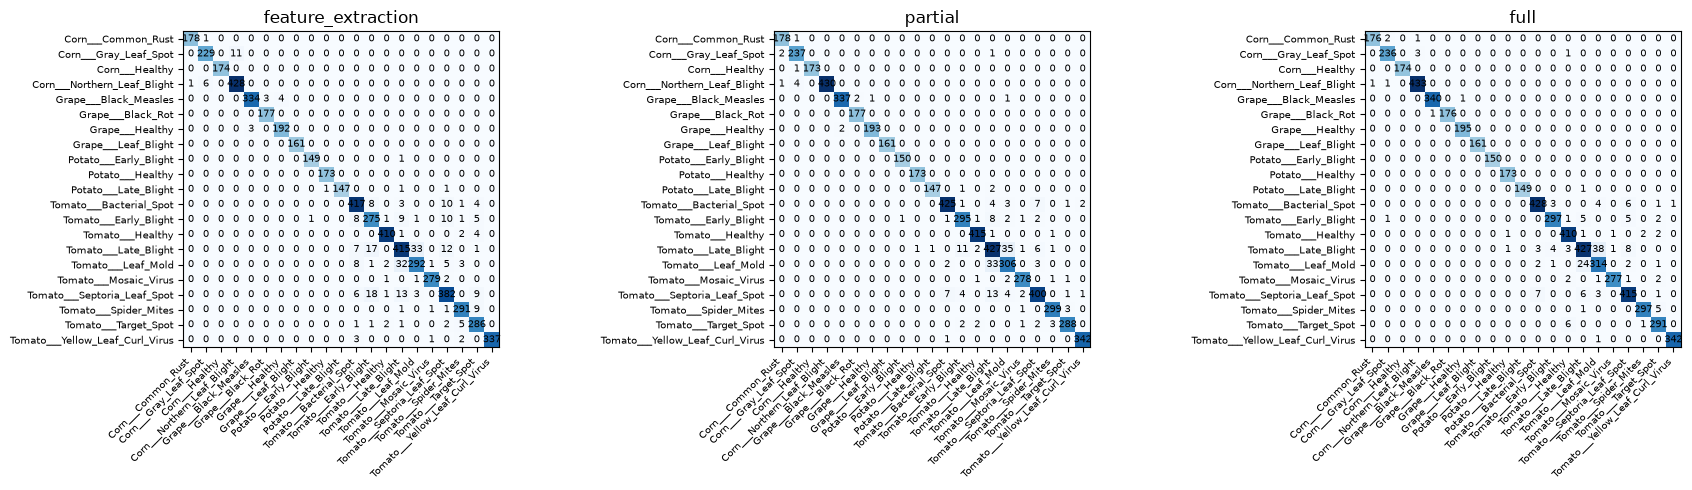

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, s in zip(axes, STRATEGIES):
    
    d = np.load(PROJECT_ROOT / "results" / f"efficientnetv2_{s}" / "preds.npz")
    cm = confusion_matrix(d["y_true"], d["y_prob"].argmax(1))
    
    ax.imshow(cm, cmap="Blues"); ax.set_title(s)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES, fontsize=7)
    
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=7)
        
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "efficientnetv2_confusion.png", dpi=150)
plt.show()

In [19]:
with mlflow.start_run(run_name="efficientnetv2_comparison"):
    mlflow.set_tags({"stage": "summary", "model": TIMM_NAME})
    for f in ["efficientnetv2_curves.png", "efficientnetv2_confusion.png"]:
        mlflow.log_artifact(str(PROJECT_ROOT / "results" / "figures" / f), artifact_path="figures")
    mlflow.log_artifact(str(PROJECT_ROOT / "results" / "summary.csv"))